# 1. Getting started

`lazuli-exo` simulates exoplanet transmission spectroscopy with the **Lazuli
IFS**. Give it a showcase planet, an atmosphere scenario, and a number of
transits, and it returns the model transmission spectrum binned to the
instrument with statistical error bars, plus a spectral-template S/N.

The runtime is numpy-only, backed by precomputed lookup tables — no POSEIDON,
slicersim, jax, or astropy at import time.

<div class="alert alert-warning">

**These are toy H<sub>2</sub>/He scenarios with idealized noise.** They are
qualitative comparison material, *not* calibrated detection significances or
observing-time forecasts. See
[Known approximations](../user_guide/concepts.rst) before quoting any number
from this notebook.

</div>

This notebook covers the whole `observe → detect → plot` loop.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__file__)

lazuli_exo /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/__init__.py


## What is available

The committed tables ship 14 showcase targets, each with the same five
scenarios. `list_planets()` and `list_scenarios()` read the table index —
they never touch the model files themselves.

In [2]:
planets = lazuli_exo.list_planets()
print(f"{len(planets)} showcase targets\n")
for p in planets:
    print(f"  {p:14s} {lazuli_exo.list_scenarios(p)}")

14 showcase targets

  GJ 1214 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  GJ 3470 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HAT-P-11 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HD 189733 b    ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  HD 209458 b    ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  K2-18 b        ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  LHS 1140 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  TOI-270 d      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  TRAPPIST-1 e   ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-107 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-12 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-121 b     ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-39 b      ['clear', 'cloudy', 'flat', 'hazy', 'high_metallicity']
  WASP-96 b      ['clear', 'cl

## A single observation

`observe()` is the one entry point you need. It takes a planet name, a
scenario, the number of transits to co-add, and the resolving power `R` to
bin the spectrum to.

In [3]:
obs = lazuli_exo.observe("WASP-39 b", scenario="clear",
                         n_transits=1, R=100)
obs

SimulatedSpectrum(planet='WASP-39 b', scenario='clear', n_transits=1, R=100, wavelength=array([0.40199402, 0.40601396, 0.4100741 , 0.41417484, 0.41831659,
       0.42249975, 0.42672475, 0.430992  , 0.43530192, 0.43965494,
       0.44405149, 0.448492  , 0.45297692, 0.45750669, 0.46208176,
       0.46670258, 0.4713696 , 0.4760833 , 0.48084413, 0.48565257,
       0.4905091 , 0.49541419, 0.50036833, 0.50537202, 0.51042574,
       0.51552999, 0.52068529, 0.52589215, 0.53115107, 0.53646258,
       0.5418272 , 0.54724548, 0.55271793, 0.55824511, 0.56382756,
       0.56946584, 0.57516049, 0.5809121 , 0.58672122, 0.59258843,
       0.59851432, 0.60449946, 0.61054446, 0.6166499 , 0.6228164 ,
       0.62904456, 0.63533501, 0.64168836, 0.64810524, 0.65458629,
       0.66113216, 0.66774348, 0.67442091, 0.68116512, 0.68797677,
       0.69485654, 0.70180511, 0.70882316, 0.71591139, 0.7230705 ,
       0.73030121, 0.73760422, 0.74498026, 0.75243007, 0.75995437,
       0.76755391, 0.77522945, 0.78298174

## Anatomy of a `SimulatedSpectrum`

The returned object is a plain dataclass. The three arrays you will use most
are `wavelength`, `depth`, and `depth_err`; `model_wavelength` /
`model_depth` keep the native-resolution model for overplotting.

In [4]:
for name in ["wavelength", "depth", "depth_err",
                       "model_wavelength", "model_depth"]:
    arr = getattr(obs, name)
    print(f"{name:18s} shape={str(arr.shape):8s} "
          f"[{arr.min():.6g}, {arr.max():.6g}]")

print()
print(f"{'flat_depth':18s} {obs.flat_depth:.6g}   "
      "# (Rp/Rs)^2 baseline from the 'flat' table")
print(f"{'R':18s} {obs.R}")
print(f"{'n_transits':18s} {obs.n_transits}")

wavelength         shape=(145,)   [0.401994, 1.6846]
depth              shape=(145,)   [0.0214891, 0.0249404]
depth_err          shape=(145,)   [6.9211e-05, 0.000287698]
model_wavelength   shape=(14427,) [0.400031, 1.69296]
model_depth        shape=(14427,) [0.0212144, 0.0299943]

flat_depth         0.0212285   # (Rp/Rs)^2 baseline from the 'flat' table
R                  100
n_transits         1


The binned grid is constant-resolving-power, so bin width grows with
wavelength. `depth` is the *noiseless* model averaged into those bins;
`depth_err` is the per-bin 1-sigma uncertainty.

In [5]:
dlam = np.diff(obs.wavelength)
print(f"{obs.wavelength.size} bins from {obs.wavelength[0]:.3f} "
      f"to {obs.wavelength[-1]:.3f} um")
print(f"bin width: {dlam[0] * 1e3:.2f} nm at the blue end, "
      f"{dlam[-1] * 1e3:.2f} nm at the red end")
print(f"R implied at mid-band: "
      f"{obs.wavelength[len(dlam) // 2] / dlam[len(dlam) // 2]:.0f}")

print(f"\ndepth_err: median {np.median(obs.depth_err) * 1e6:.0f} ppm, "
      f"best {obs.depth_err.min() * 1e6:.0f} ppm, "
      f"worst {obs.depth_err.max() * 1e6:.0f} ppm")

145 bins from 0.402 to 1.685 um
bin width: 4.02 nm at the blue end, 16.68 nm at the red end
R implied at mid-band: 100

depth_err: median 98 ppm, best 69 ppm, worst 288 ppm


## Plotting

`obs.plot()` overlays the noiseless high-resolution model with one simulated
noisy realization at the binned resolution. It needs the `[plot]` extra
(matplotlib).

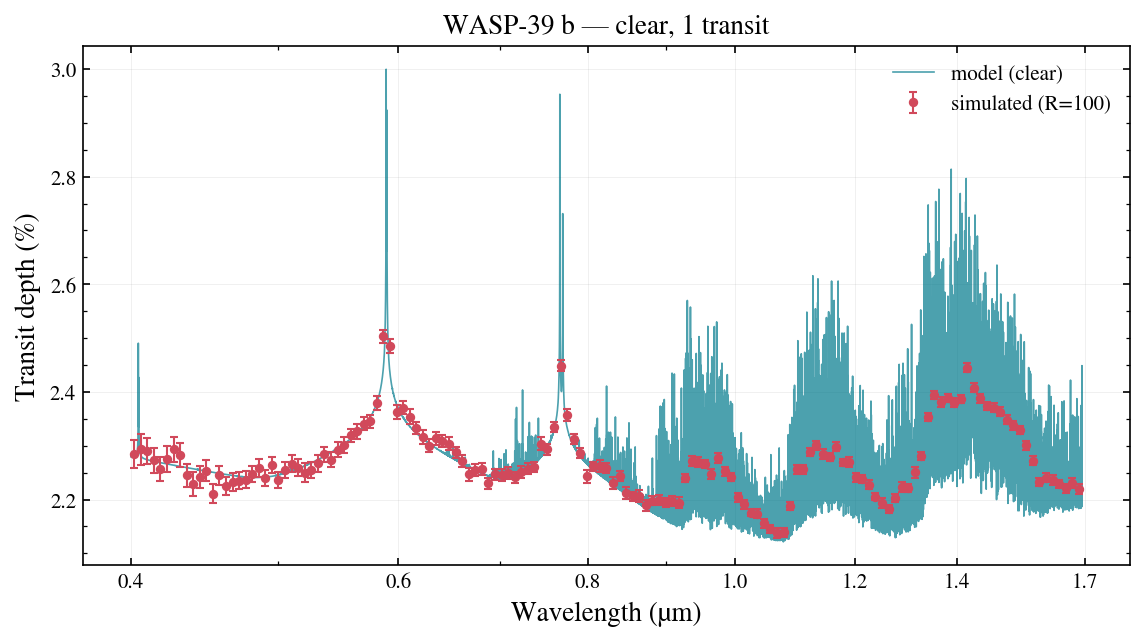

In [6]:
obs.plot(seed=0)
plt.show()

## Noise realizations

`depth` and `depth_err` are deterministic — the *noise* is drawn on demand by
`simulate_points(seed)`. Passing a seed makes a realization reproducible,
which is how the web demo and these notebooks stay stable across runs.

In [7]:
a = obs.simulate_points(seed=0)
b = obs.simulate_points(seed=0)
c = obs.simulate_points(seed=1)

assert np.array_equal(a, b), "same seed must give the same realization"
assert not np.array_equal(a, c), "different seeds must differ"

resid = (a - obs.depth) / obs.depth_err
print(f"same seed reproduces:      {np.array_equal(a, b)}")
print(f"different seed differs:    {not np.array_equal(a, c)}")
print(f"\nresiduals in sigma units: mean {resid.mean():+.3f}, "
      f"std {resid.std():.3f}  (expect ~0 and ~1)")

same seed reproduces:      True
different seed differs:    True

residuals in sigma units: mean +0.080, std 0.954  (expect ~0 and ~1)


## Detection diagnostics

`obs.detect()` returns a **matched-template amplitude S/N** of the model
against the best-fit flat line, under a diagonal covariance.

<div class="alert alert-warning">

`template_snr_diagonal` is *not* a calibrated detection significance — there
is no null/alternative likelihood ratio, no nuisance model, no covariance,
and no false-positive calibration. The per-band values are the same statistic
restricted to fixed wavelength masks; they mix every species in the mask plus
haze/cloud/continuum structure, and the masks overlap. They are **not**
molecule detections.

</div>

In [8]:
result = obs.detect()

print(f"template_snr_diagonal: {result['template_snr_diagonal']:.1f}\n")
print("band_snr (band-restricted template norms, NOT detections):")
for mol, snr in sorted(result["band_snr"].items(),
                       key=lambda kv: -kv[1]):
    print(f"  {mol:5s} {snr:7.1f}")

template_snr_diagonal: 85.2

band_snr (band-restricted template norms, NOT detections):
  H2O      57.3
  CO2      32.8
  Na       28.9
  CH4      24.8
  K        21.0


The band masks themselves live in `lazuli_exo.detect.BAND_MASKS`. Note that
H2O and CH4 both cover 1.10–1.20 µm — overlapping masks are exactly why these
are not per-molecule detections.

In [9]:
from lazuli_exo.detect import BAND_MASKS

for mol, spans in BAND_MASKS.items():
    pretty = ", ".join(f"{lo:.3f}-{hi:.3f}" for lo, hi in spans)
    print(f"  {mol:5s} {pretty} um")

  Na    0.575-0.605 um
  K     0.755-0.785 um
  H2O   0.900-1.000, 1.100-1.200, 1.300-1.550 um
  CH4   0.860-0.910, 1.100-1.200, 1.600-1.700 um
  CO2   1.420-1.460, 1.560-1.620 um


## Where the numbers came from

Every observation carries the provenance of the tables it was built from in
`obs.meta` — the POSEIDON model settings under `"model"` and the slicersim
noise settings under `"noise"`. This is the first place to look when a number
surprises you.

In [10]:
for section in ["model", "noise"]:
    print(f"meta[{section!r}]:")
    for k, v in obs.meta[section].items():
        print(f"  {k:20s} {v}")
    print()

meta['model']:
  generator            make_model_tables.py
  created              2026-08-29
  T_eq_K               1166.0
  T_iso_K              1166.0
  T_clamped            False
  cloud_model          cloud-free
  cloud_type           None
  cloud_params         []
  C_to_O               0.55
  log_Met              0.0
  planet               WASP-39 b
  scenario             clear

meta['noise']:
  generator            make_noise_tables.py
  created              2026-10-04
  J_mag                10.663
  norm_band            2massj
  stellar_grid         phoenix
  slicersim_version    1.0.0
  instrument           lazuli_cbe
  band                 J
  sncosmo_band         2massj
  mag_input            10.663
  mag_system           vega
  vega_ab_offset       0.8993018775290533
  mag_ab               11.562301877529054
  t14_s                10091.52
  t_obs_s              90.56
  default_nmd          [16, 8, 0]
  nmd_used             [4, 8, 0]
  nramps               1
  nsaturated_de

## Summary

- `lazuli_exo.observe(planet, scenario, n_transits, R)` is the entry point;
  it returns a `SimulatedSpectrum`.
- `.depth` / `.depth_err` are noiseless model and 1-sigma errors;
  `.simulate_points(seed)` draws a reproducible noisy realization.
- `.detect()` gives a template S/N — a comparison statistic, not a
  significance.
- `.meta` records exactly which model and noise assumptions produced the
  numbers.

Next: [scenarios](02_scenarios.ipynb) — what the five atmosphere scenarios
mean and how they differ.